# OULAD data exploration

This notebook explores the cleaned OULAD tables descriptively before model training. It asks what the data contains, how outcomes vary across enrollments, how assessment scores are distributed, and what information is missing.

The charts describe associations. They do not prove that activity caused an outcome, that clicks equal study duration, or that one group is inherently more capable than another.

## Notebook map

- `02_oulad_processing_and_features.ipynb` documents cleaning and feature construction.
- This notebook explores the cleaned tables and their relationships.
- `03_oulad_baseline_comparison.ipynb` trains and compares the four baseline models.

The exploration notebook intentionally keeps descriptive analysis separate from model selection.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'src/data/cleaner.py').exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.cleaner import clean_oulad_tables
from src.data.loader import load_clean_table, load_oulad_tables

RAW_DIR = ROOT / 'data/raw/oulad'
PROCESSED_DIR = ROOT / 'data/processed/oulad'
TABLE_DIR = PROCESSED_DIR if (PROCESSED_DIR / 'studentInfo.csv').exists() else RAW_DIR
TABLE_NAMES = ['studentInfo', 'studentRegistration', 'assessments', 'studentAssessment']

if TABLE_DIR == PROCESSED_DIR:
    tables = {name: load_clean_table(name, TABLE_DIR) for name in TABLE_NAMES}
else:
    tables = clean_oulad_tables(load_oulad_tables(RAW_DIR))

print(f'Data directory: {TABLE_DIR}')
print(f'Tables loaded: {list(tables)}')

Data directory: D:\AI PROJECTS\C++\Smart-Study-Planner\data\processed\oulad
Tables loaded: ['studentInfo', 'studentRegistration', 'assessments', 'studentAssessment']


## 1. Population and table overview

An OULAD enrollment is a student taking a course presentation. A student can therefore contribute more than one enrollment. Assessment definitions and assessment results are separate row units.

In [2]:
table_summary = pd.DataFrame(
    [{'table': name, 'rows': len(frame), 'columns': len(frame.columns)}
     for name, frame in tables.items()]
).sort_values('table')
display(table_summary.reset_index(drop=True))

student_info = tables['studentInfo']
student_assessment = tables['studentAssessment']
assessments = tables['assessments']
registration = tables['studentRegistration']

,table,rows,columns
0,assessments,206,6
1,studentAssessment,173912,5
2,studentInfo,32593,12
3,studentRegistration,32593,5


## 2. Outcome distribution

This section shows the final-result composition of the enrollment population. The risk target used later groups Fail and Withdrawn together, but the original four outcome categories are kept here so that the grouping is transparent.

,enrollments
final_result,
Distinction,3024
Pass,12361
Fail,7052
Withdrawn,10156


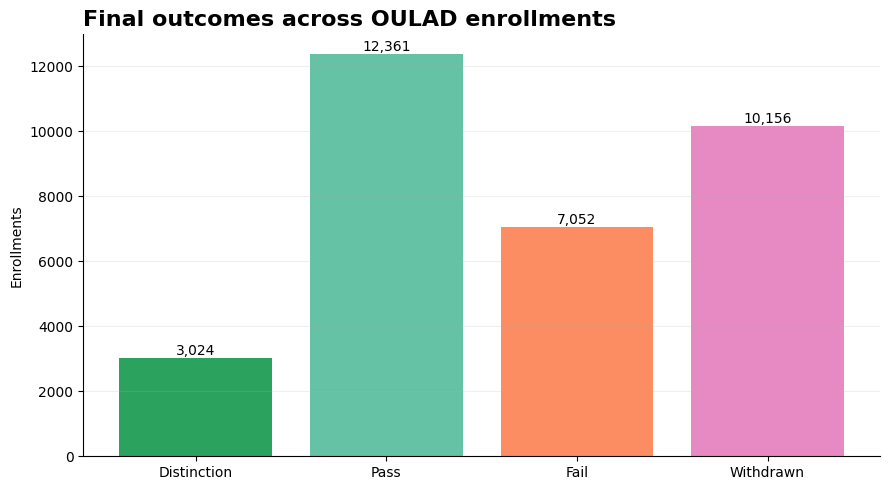

In [3]:
outcome_order = ['Distinction', 'Pass', 'Fail', 'Withdrawn']
outcomes = student_info['final_result'].value_counts().reindex(outcome_order, fill_value=0)
display(outcomes.rename_axis('final_result').to_frame('enrollments'))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(outcomes.index, outcomes.values, color=['#2ca25f', '#66c2a4', '#fc8d62', '#e78ac3'])
ax.set_title('Final outcomes across OULAD enrollments', loc='left', fontsize=16, weight='bold')
ax.set_ylabel('Enrollments')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{int(bar.get_height()):,}',
            ha='center', va='bottom')
fig.tight_layout()
plt.show()

## 3. Outcomes by course presentation

Course and presentation differences are important context for any model. A presentation is a specific course offering, so outcome rates should be compared with their enrollment denominators rather than treated as universal course effects.

In [4]:
by_presentation = (
    student_info.assign(
        risk=student_info['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
    )
    .groupby(['code_module', 'code_presentation'], as_index=False)
    .agg(enrollments=('id_student', 'size'), risk_rate=('risk', 'mean'))
)
by_presentation['risk_rate_percent'] = by_presentation['risk_rate'] * 100
display(by_presentation.sort_values('risk_rate', ascending=False).head(15))

,code_module,code_presentation,enrollments,risk_rate,risk_rate_percent
6,CCC,2014B,1936,0.657541,65.754132
10,DDD,2014B,1228,0.609935,60.993485
8,DDD,2013B,1303,0.608596,60.859555
7,CCC,2014J,2498,0.593675,59.367494
9,DDD,2013J,1938,0.572239,57.223942
17,FFF,2014B,1500,0.564000,56.400000
11,DDD,2014J,1803,0.560732,56.073211
4,BBB,2014B,1613,0.549287,54.928704
2,BBB,2013B,1767,0.545557,54.555744
18,FFF,2014J,2365,0.527696,52.769556


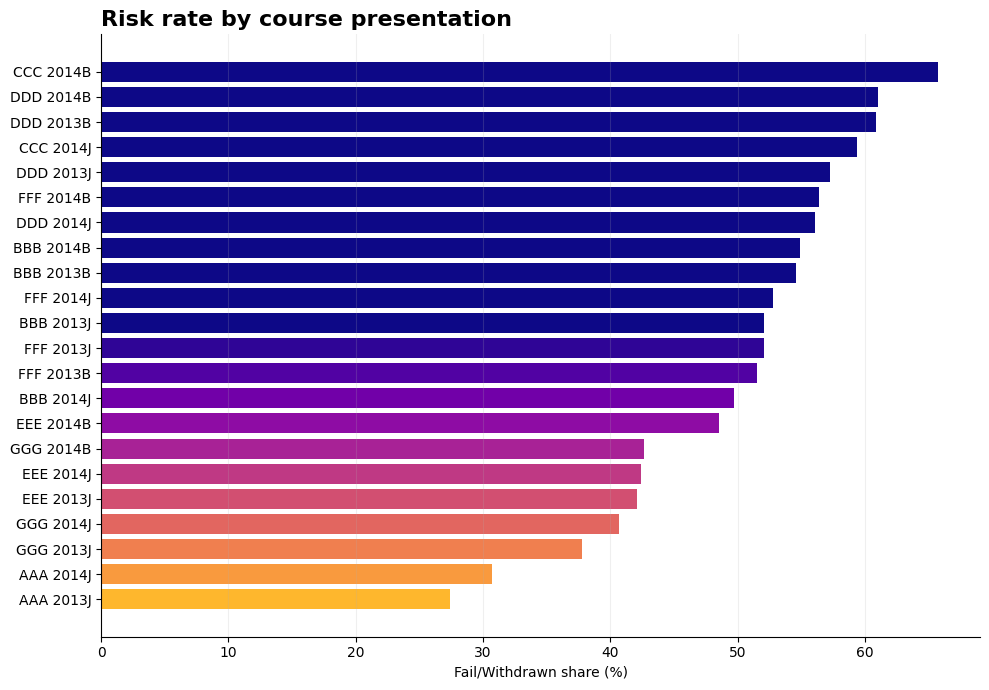

In [5]:
presentation_plot = by_presentation.sort_values('risk_rate_percent')
labels = presentation_plot['code_module'] + ' ' + presentation_plot['code_presentation']
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(labels, presentation_plot['risk_rate_percent'], color=plt.cm.plasma_r(
    range(40, 40 + 20 * len(presentation_plot), 20)
))
ax.set_title('Risk rate by course presentation', loc='left', fontsize=16, weight='bold')
ax.set_xlabel('Fail/Withdrawn share (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

## 4. Demographic and enrollment attributes

These plots are descriptive group summaries. They should not be used to infer individual ability or causal effects, and sensitive attributes require careful governance before being used in a deployed model.

In [6]:
group_columns = [column for column in ['age_band', 'highest_education', 'gender', 'disability'] if column in student_info]
group_summaries = {}
for column in group_columns:
    summary = (
        student_info.assign(risk=student_info['final_result'].isin(['Fail', 'Withdrawn']).astype(int))
        .groupby(column, dropna=False)
        .agg(enrollments=('id_student', 'size'), risk_rate=('risk', 'mean'))
        .sort_values('risk_rate', ascending=False)
    )
    summary['risk_rate_percent'] = summary['risk_rate'] * 100
    group_summaries[column] = summary
    display(Markdown(f'**{column}**'))
    display(summary.reset_index())

**age_band**

,age_band,enrollments,risk_rate,risk_rate_percent
0,0-35,22944,0.549686,54.968619
1,35-55,9433,0.478427,47.842680
2,55<=,216,0.384259,38.425926


**highest_education**

,highest_education,enrollments,risk_rate,risk_rate_percent
0,No Formal quals,347,0.703170,70.317003
1,Lower Than A Level,13158,0.611491,61.149111
2,A Level or Equivalent,14045,0.479672,47.967248
3,HE Qualification,4730,0.438266,43.826638
4,Post Graduate Qualification,313,0.345048,34.504792


**gender**

,gender,enrollments,risk_rate,risk_rate_percent
0,M,17875,0.538126,53.812587
1,F,14718,0.515627,51.562712


**disability**

,disability,enrollments,risk_rate,risk_rate_percent
0,Y,3164,0.618521,61.852086
1,N,29429,0.518230,51.823032


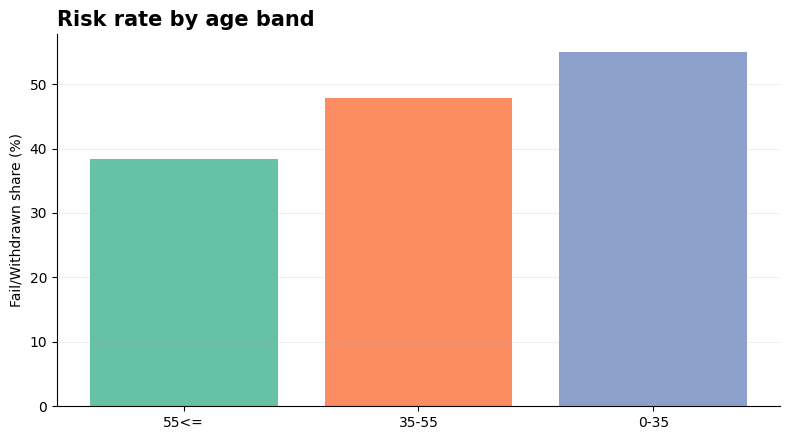

In [7]:
if 'age_band' in group_summaries:
    age_plot = group_summaries['age_band'].sort_values('risk_rate_percent')
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(age_plot.index.astype(str), age_plot['risk_rate_percent'],
           color=['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3'])
    ax.set_title('Risk rate by age band', loc='left', fontsize=15, weight='bold')
    ax.set_ylabel('Fail/Withdrawn share (%)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    plt.show()

## 5. Assessment scores

Assessment results are joined to their definitions so scores can be examined by assessment type. A missing score is not a zero score. The final outcome is shown as a grouping variable for description, not as an input to these plots.

In [8]:
score_table = student_assessment.merge(
    assessments[['id_assessment', 'code_module', 'code_presentation', 'assessment_type']],
    on='id_assessment',
    how='inner',
).merge(
    student_info[['id_student', 'code_module', 'code_presentation', 'final_result']],
    on=['id_student', 'code_module', 'code_presentation'],
    how='inner',
)
display(score_table.groupby('assessment_type')['score'].agg(['count', 'mean', 'median', 'std']).reset_index())

,assessment_type,count,mean,median,std
0,CMA,70527,81.027053,82.0,17.836026
1,Exam,4959,65.572898,67.0,20.579186
2,TMA,98253,72.563392,76.0,18.432823


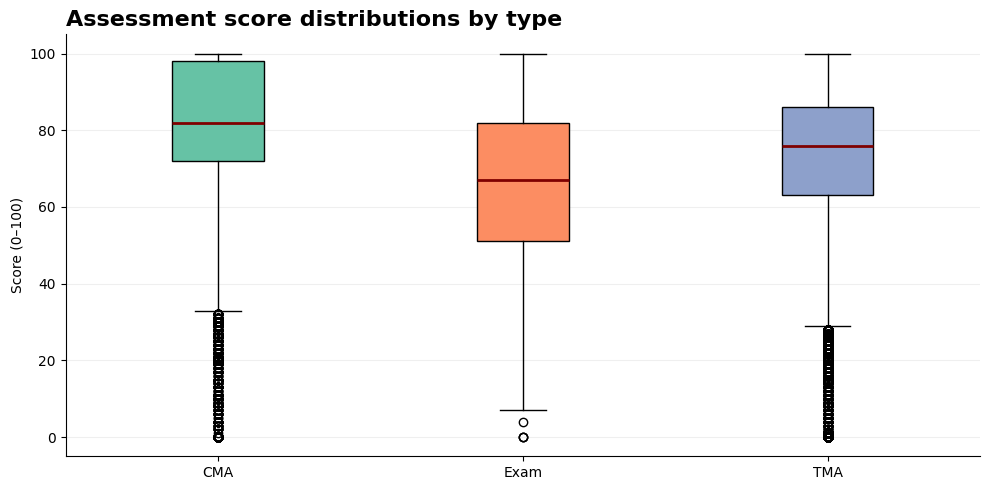

In [9]:
score_plot = score_table.dropna(subset=['score'])
score_types = sorted(score_plot['assessment_type'].dropna().unique())
groups = [score_plot.loc[score_plot['assessment_type'] == kind, 'score'] for kind in score_types]
fig, ax = plt.subplots(figsize=(10, 5))
box = ax.boxplot(groups, tick_labels=score_types, patch_artist=True,
                 medianprops={'color': '#7f0000', 'linewidth': 2})
for patch, color in zip(box['boxes'], plt.cm.Set2(range(len(box['boxes'])))):
    patch.set_facecolor(color)
ax.set_title('Assessment score distributions by type', loc='left', fontsize=16, weight='bold')
ax.set_ylabel('Score (0–100)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 6. Registration timing

Registration dates are relative to the course start in OULAD. This view compares the supplied registration field across outcome groups; it does not mean that registering earlier causes a better result.

,count,mean,median
risk_group,,,
Fail/Withdrawn,18620,-71.744791,-59.0
Pass/Distinction,16092,-66.300336,-53.0


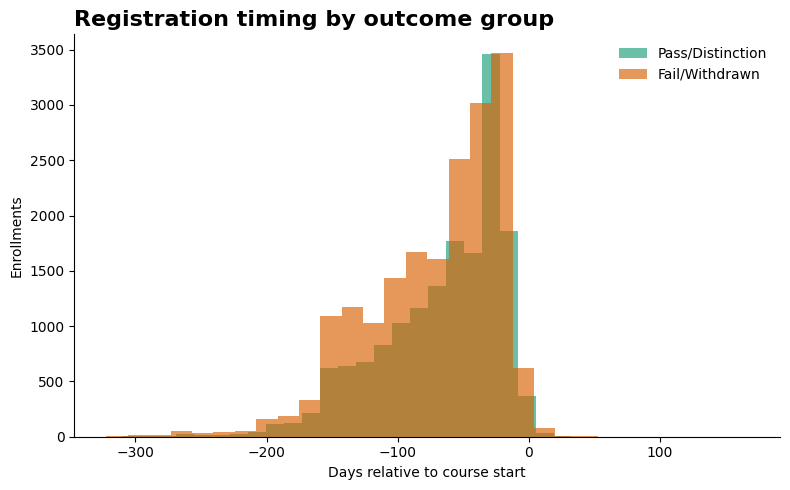

In [10]:
registration_plot = registration.merge(
    student_info[['id_student', 'code_presentation', 'final_result']],
    on=['id_student', 'code_presentation'],
    how='inner',
)
registration_plot['risk_group'] = registration_plot['final_result'].isin(['Fail', 'Withdrawn']).map(
    {False: 'Pass/Distinction', True: 'Fail/Withdrawn'}
)
registration_summary = registration_plot.groupby('risk_group')['date_registration'].agg(['count', 'mean', 'median'])
display(registration_summary)

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in [('Pass/Distinction', '#1b9e77'), ('Fail/Withdrawn', '#d95f02')]:
    values = registration_plot.loc[registration_plot['risk_group'] == label, 'date_registration'].dropna()
    ax.hist(values, bins=30, alpha=0.65, label=label, color=color)
ax.set_title('Registration timing by outcome group', loc='left', fontsize=16, weight='bold')
ax.set_xlabel('Days relative to course start')
ax.set_ylabel('Enrollments')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## Conclusions and limitations

Use this notebook to understand the populations and relationships that feed the baseline. The analysis does not identify an optimal study duration or schedule, and it does not establish causality. Full-course assessment and activity records can contain information that would not be available at an early prediction cutoff. The next evaluation stage should use time-aware feature construction and splits.